# 03. Individual days

One page per day, **midnight to midnight (UTC)**. Raw data only, every row plotted.

| Day | Why it's here |
| --- | --- |
| **15 Jul** | **Reference day.** Armed and AUTO all day (two short MANUAL blips), steadiest navigation of the fortnight. |
| **14 Jul** | Deployment day. Moving at ~1.9 m/s while **disarmed** until 07:48. Lots of AUTO/MANUAL switching after. Four Iridium speed readings at 07:39 spike to **34 m/s**. |
| **25 Jul** | **Reboot** at 19:38 (mode 16, disarmed, position (0, 0)). Highest load of the fortnight (190 W). |
| **27 Jul** | **Starlink's last message is at 02:05.** Second **reboot** at 19:00. |
| **28 Jul** | First full day on **Iridium only**. MANUAL all day, low load, voltage climbs. |

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

plt.rcParams.update({"axes.grid": True, "grid.alpha": 0.3, "axes.spines.top": False, "axes.spines.right": False})

df = pd.read_csv("../data/scout_telemetry_2025-07.csv", na_values="null")
df["t"] = pd.to_datetime(df["created_at"], format="ISO8601", utc=True)
df = df.sort_values("t").reset_index(drop=True)
df["P_batt"] = df.voltage_battery1_v * df.current_battery1_a     # + = charging
df["P_load"] = df.voltage_battery1_v * df.current_battery2_a     # battery2 = total load
df["P_solar"] = df.voltage_battery3_v * df.current_battery3_a

LINK_COLORS = {"direct": "#1f77b4", "imt": "#ff7f0e", "globalstar": "#2ca02c"}
POWER_COLORS = {"P_solar": "#f2b701", "P_load": "#d62728", "P_batt": "#1f77b4"}
POWER_NAMES = {"P_solar": "solar", "P_load": "load", "P_batt": "battery (+ charging)"}
MODE_NAMES = {-1: "MANUAL disarmed", 0: "MANUAL armed", 10: "AUTO", 16: "INITIALISING", 17: "mode 17"}   # MANUAL split by arming (-1 = disarmed)
df["mode_arm"] = np.where((df.custom_mode == 0) & (df.custom0_arming == 0), -1, df.custom_mode)

## The days

Each page has five panels, all raw rows:
1. **Link**: one tick per message received.
2. **Battery voltage**, coloured by link.
3. **Power**: solar, load, battery net. Starlink rows are dots; Iridium load readings are crosses.
4. **Speed over ground**, coloured by link. Cropped at 4 m/s.
5. **Mode**, one tick per message. MANUAL is split into armed and disarmed.

Dashed lines mark the events from the table at the top.

In [2]:
def day_page(day, events=None):
    """Five-panel raw-data view of one day. events: {"HH:MM": label}."""
    start = pd.Timestamp(day, tz="UTC")
    end = start + pd.Timedelta(days=1)
    d = df[(df.t >= start) & (df.t < end)]
    links = list(d.groupby("communication_mode"))

    fig, axes = plt.subplots(5, 1, figsize=(14, 13), sharex=True, gridspec_kw={"height_ratios": [0.6, 1, 1.4, 1, 0.8]})
    ax_link, ax_v, ax_p, ax_s, ax_m = axes

    for i, (link, g) in enumerate(links):
        ax_link.plot(g.t, [i] * len(g), "|", ms=10, color=LINK_COLORS[link])
    ax_link.set_yticks(range(len(links)), [l for l, _ in links]); ax_link.set_ylim(-0.5, len(links) - 0.5)
    ax_link.set_title(f"{start:%a %d %b %Y} (UTC): {len(d)} rows")

    for link, g in links:
        ax_v.plot(g.t, g.voltage_battery1_v, ".", ms=2, color=LINK_COLORS[link], label=link)
        ax_s.plot(g.t, g.groundspeed_ms, ".", ms=2, color=LINK_COLORS[link], label=link)
    ax_v.set_ylabel("battery V"); ax_v.legend(markerscale=5, loc="upper left")
    ax_s.set_ylabel("speed (m/s)"); ax_s.set_ylim(0, 4)

    direct, imt = d[d.communication_mode == "direct"], d[d.communication_mode == "imt"]
    for col in ["P_solar", "P_load", "P_batt"]:
        ax_p.plot(direct.t, direct[col], ".", ms=2, color=POWER_COLORS[col], label=POWER_NAMES[col])
    ax_p.plot(imt.t, imt.P_load, "x", ms=5, color=POWER_COLORS["P_load"], label="load (Iridium)")
    ax_p.axhline(0, color="grey", lw=0.8)
    ax_p.set_ylabel("W"); ax_p.legend(markerscale=3, loc="upper left")

    modes = sorted(d.mode_arm.dropna().unique())
    for i, mode in enumerate(modes):
        g = d[d.mode_arm == mode]
        ax_m.plot(g.t, [i] * len(g), "|", ms=8, color="k")
    ax_m.set_yticks(range(len(modes)), [MODE_NAMES.get(int(m), int(m)) for m in modes])
    ax_m.set_ylim(-0.5, len(modes) - 0.5)

    for hhmm, label in (events or {}).items():
        t = start + pd.Timedelta(hhmm + ":00")
        for ax in axes:
            ax.axvline(t, color="k", ls="--", lw=1)
        ax_v.annotate(f" {hhmm} {label}", (t, 0.98), xycoords=("data", "axes fraction"), rotation=90,
                      ha="right", va="top", fontsize=9, bbox=dict(fc="white", ec="none", alpha=0.8, pad=1))

    ax_m.set_xlim(start, end)
    ax_m.xaxis.set_major_locator(mdates.HourLocator(byhour=range(0, 24, 3)))
    ax_m.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M"))
    plt.tight_layout(); plt.show()

### 15 Jul: a normal day (reference)
Picked as the most consistent navigation day: armed all day and AUTO in every Iridium message, median speed 1.0 m/s. Starlink catches two short MANUAL blips (~10:30 and ~19:10) that Iridium is too sparse to see. Use it as the baseline when looking at the odd days below.

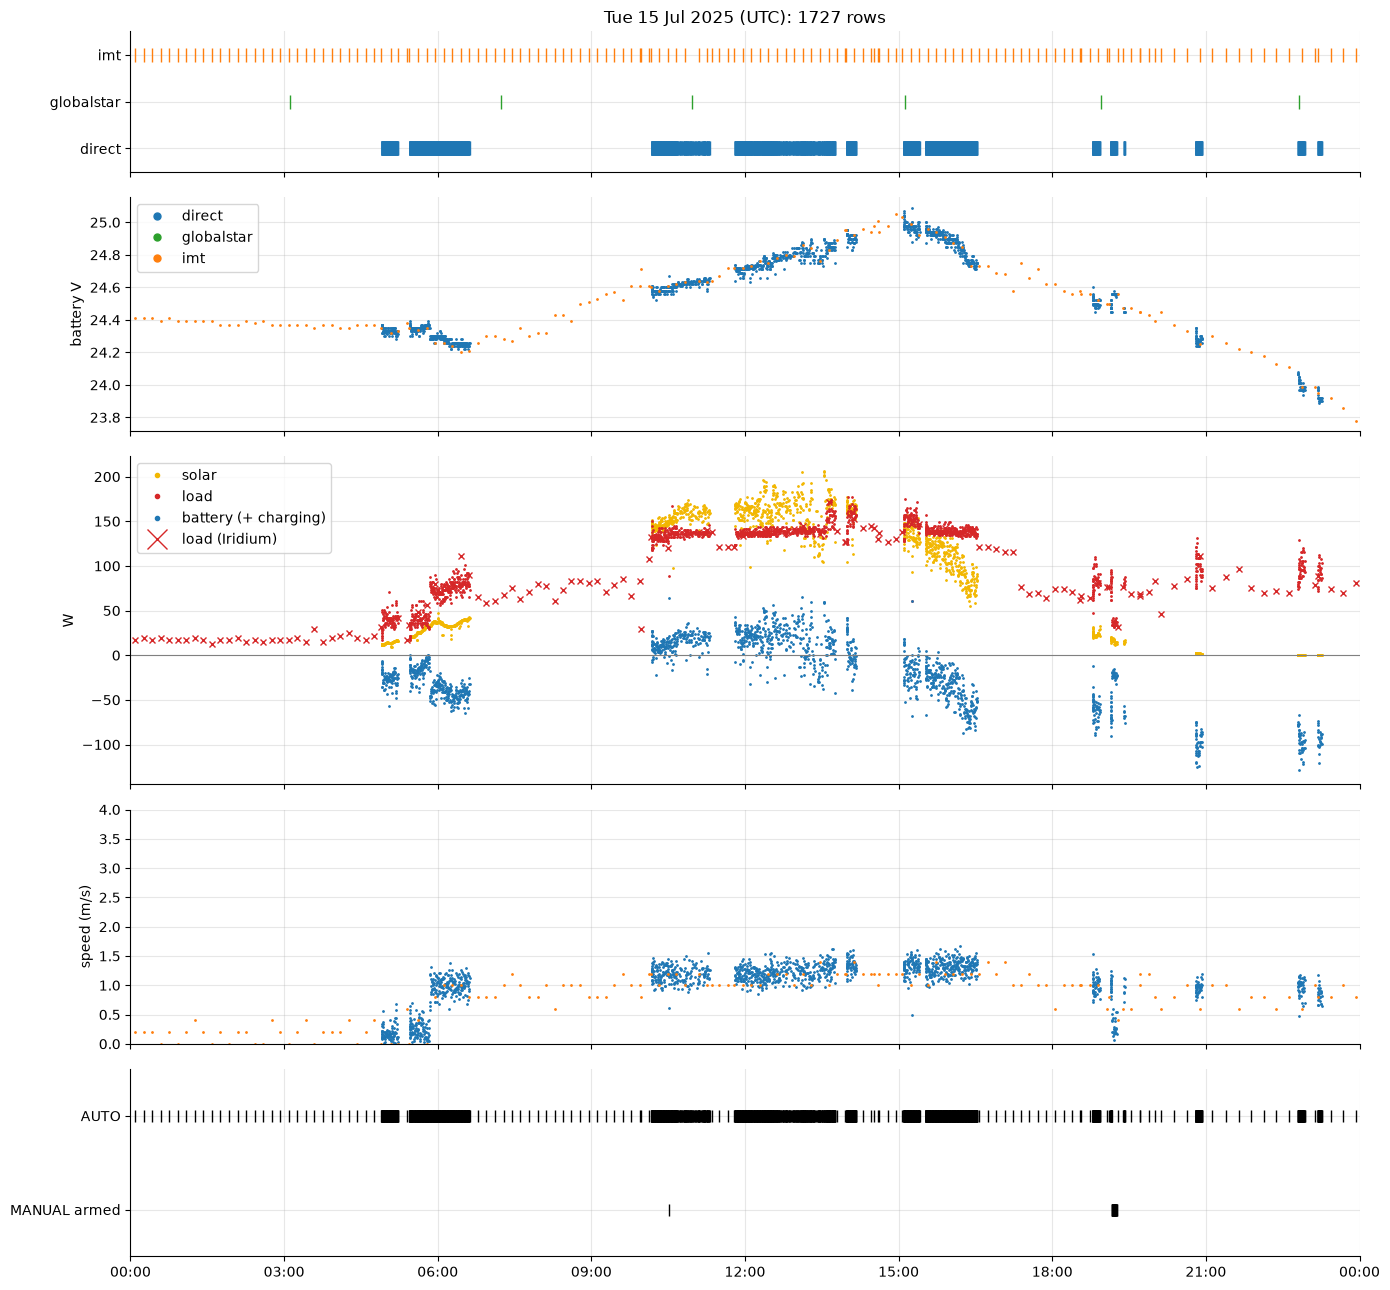

In [3]:
day_page("2025-07-15")

### 14 Jul: deployment day
Disarmed but moving at ~1.9 m/s until it arms at 07:48 (too fast for drift, so probably a transit or tow). Then short bursts of AUTO, MANUAL and disarming until mid-afternoon: it looks like commissioning tests. The bogus Iridium speed spikes at 07:39 are off the top of the speed panel. Starlink runs almost all day, so this day has the most rows by far.

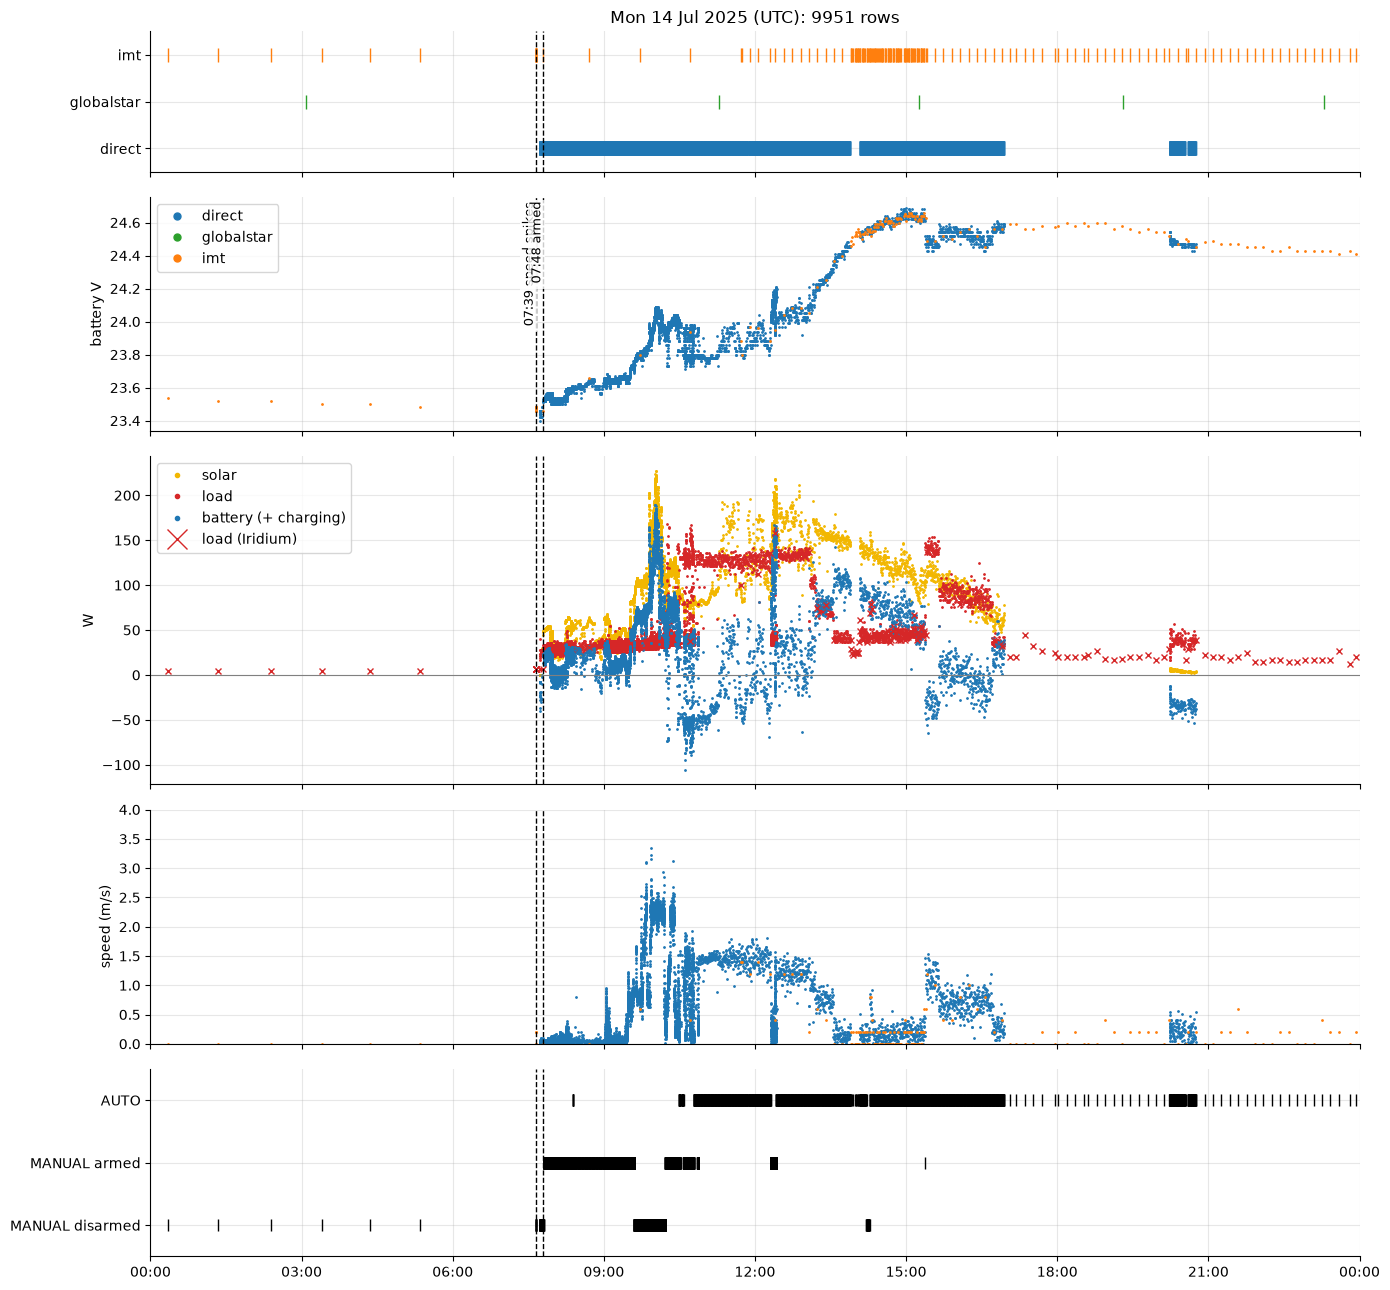

In [4]:
day_page("2025-07-14", {"07:39": "speed spikes", "07:48": "armed"})

### 25 Jul: the first reboot
MANUAL most of the day, mode 17 from 17:57, disarmed at 19:37 and **rebooted at 19:38** (mode 16, position (0, 0)). It re-arms at 20:02, then tries AUTO and mode 17 in the evening. That evening has the highest load of the fortnight (~190 W).

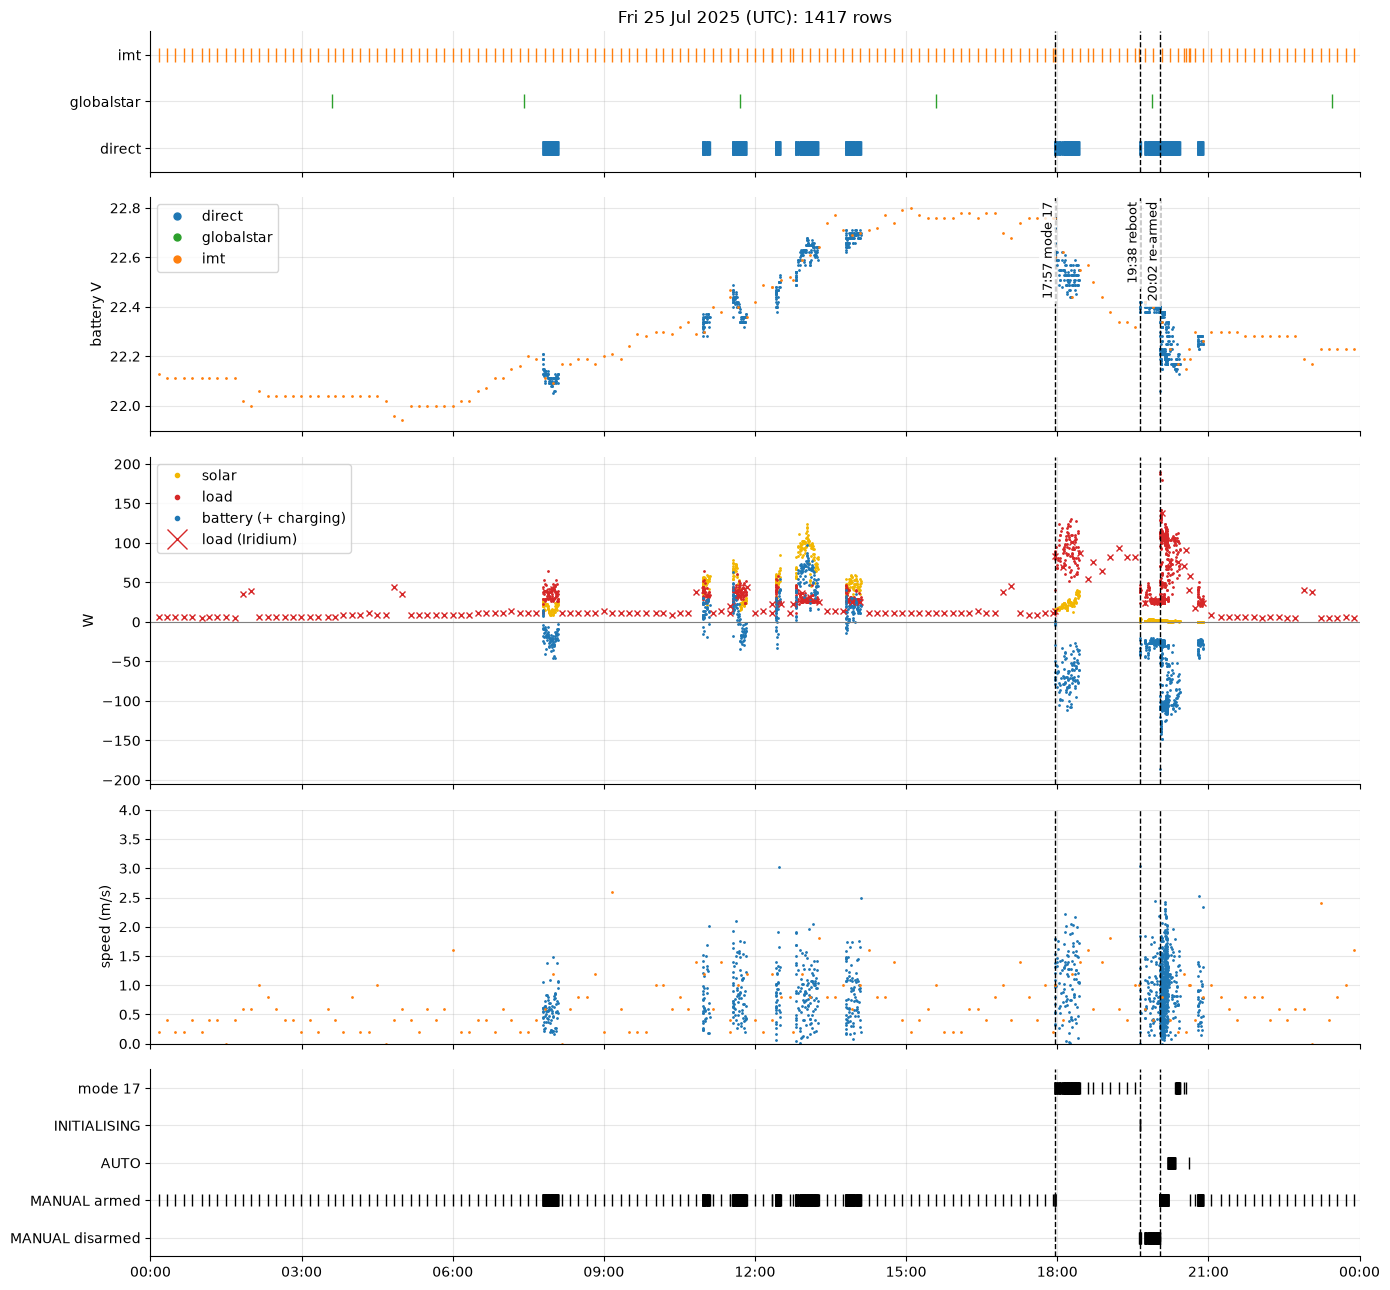

In [5]:
day_page("2025-07-25", {"17:57": "mode 17", "19:38": "reboot", "20:02": "re-armed"})

### 27 Jul: Starlink goes dark
Starlink's last message is at **02:05**. After that only Iridium (and the odd Globalstar) reports, so solar, battery current and temperature disappear from the plots. The median load drops from ~28 W to ~9 W: Starlink alone was ~20 W of it. A second **reboot** at 19:00.

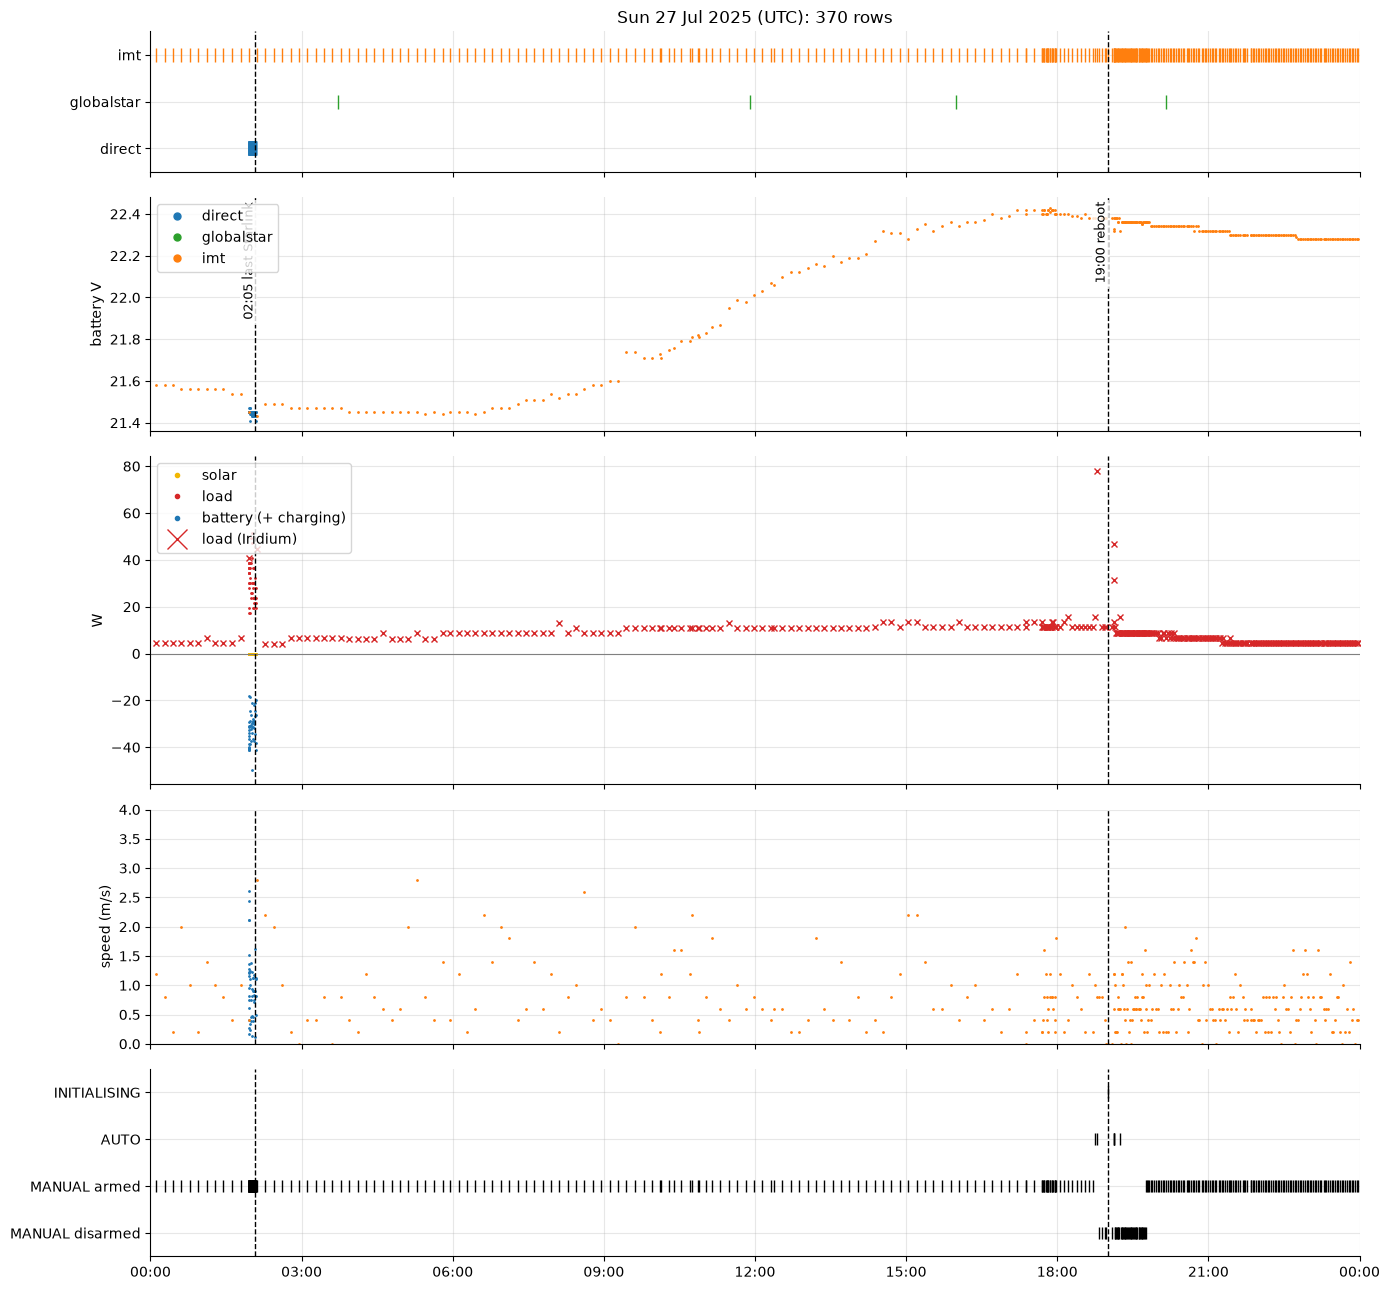

In [6]:
day_page("2025-07-27", {"02:05": "last Starlink", "19:00": "reboot"})

### 28 Jul: Iridium only, battery recovering
No Starlink all day, MANUAL, load ~10 W. With almost nothing drawing power, the sun charges the battery: voltage ends ~1.1 V higher than it started (29 Jul: +1.4 V, then it levels off ~25.2 V on 30 Jul). Speed here is drift only.

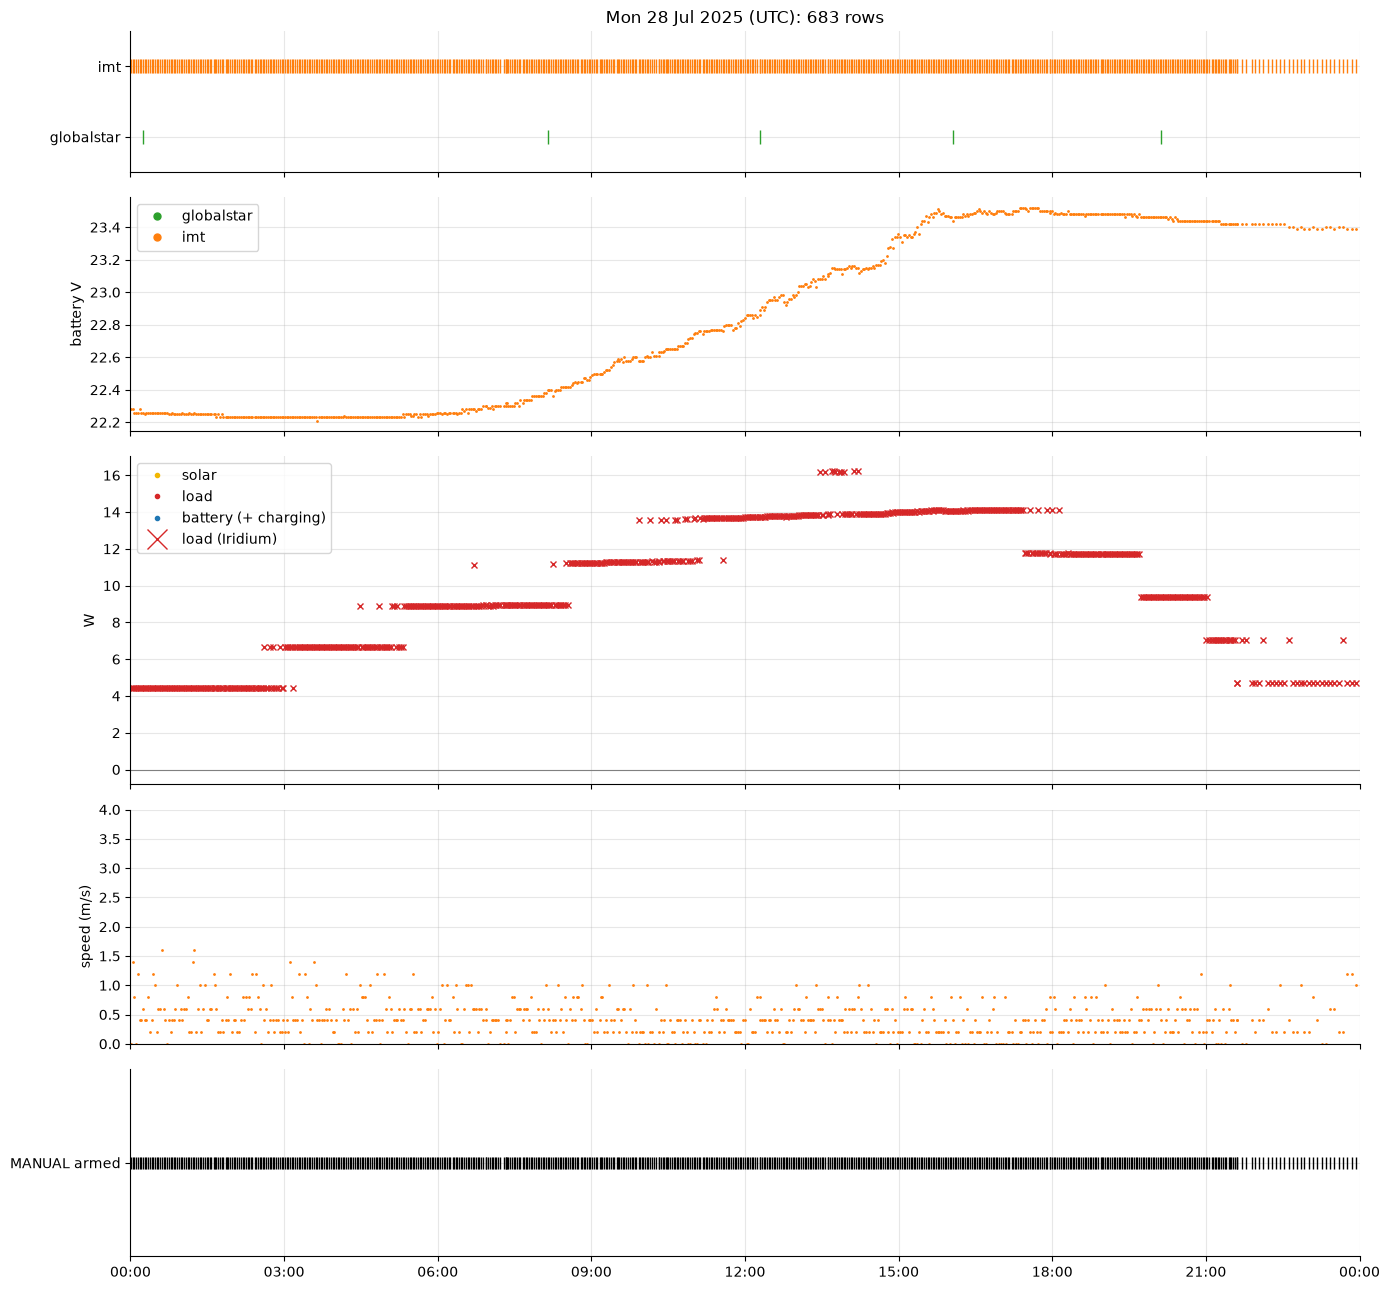

In [7]:
day_page("2025-07-28")